# 04 - Imbalance handling and churn models
Four classifiers (Logistic Regression, CART, Random Forest, XGBoost) x three imbalance options (none, class weights, SMOTE), all on the 8 selected churn features. Everything is fitted on TRAIN; TEST is only used for the final scores.

**Important:** in TRAIN, churners are the **majority** (62%). The minority class is 'stays', so class weights and SMOTE give extra weight to / create synthetic **non-churners**. With a 62/38 split we expect only small effects. SMOTE is placed inside an imblearn Pipeline, so it only resamples training folds.

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import config
import churn_models as cm

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
pd.set_option('display.max_colwidth', 70)

X_train, y_train, X_test, y_test, train, test = cm.load_churn_data()
print('Features:', list(X_train.columns))
print(f'Train churn rate: {y_train.mean():.3f}   Test churn rate: {y_test.mean():.3f}')

Features: ['frequency', 'monetary', 'purchase_regularity', 'tenure_days', 'recency', 'seg_Champions', 'unique_products', 'spend_trend']
Train churn rate: 0.620   Test churn rate: 0.500


## 1. Train every model x imbalance method
Random Forest and XGBoost get a small GridSearchCV (StratifiedKFold, 5 folds, ROC-AUC). The other models get a plain 5-fold CV score. `cv_roc_auc_train` comes from TRAIN only.

In [2]:
table, fitted, probabilities = cm.run_all_models(X_train, y_train, X_test, y_test, train, test)
cm.check_leakage_alarm(table)

done: Logistic Regression | none               CV ROC-AUC 0.772  test ROC-AUC 0.764
done: Logistic Regression | class_weight       CV ROC-AUC 0.772  test ROC-AUC 0.765


done: Logistic Regression | smote              CV ROC-AUC 0.771  test ROC-AUC 0.767
done: CART | none                              CV ROC-AUC 0.748  test ROC-AUC 0.729


done: CART | class_weight                      CV ROC-AUC 0.744  test ROC-AUC 0.729


done: CART | smote                             CV ROC-AUC 0.755  test ROC-AUC 0.733


done: Random Forest | none                     CV ROC-AUC 0.772  test ROC-AUC 0.759


done: Random Forest | class_weight             CV ROC-AUC 0.772  test ROC-AUC 0.761


done: Random Forest | smote                    CV ROC-AUC 0.771  test ROC-AUC 0.765


done: XGBoost | none                           CV ROC-AUC 0.773  test ROC-AUC 0.762


done: XGBoost | class_weight                   CV ROC-AUC 0.772  test ROC-AUC 0.759


done: XGBoost | smote                          CV ROC-AUC 0.772  test ROC-AUC 0.764
Leakage alarm check: no model above test ROC-AUC 0.9 (max 0.767)


In [3]:
table.to_csv(config.TABLES_DIR / 'churn_model_comparison.csv', index=False)
table.drop(columns=['best_params']).round(3)

,model,imbalance,cv_roc_auc_train,precision,recall,f1,roc_auc,pr_auc,mean_pred_prob,actual_churn_rate,TN,FP,FN,TP
0,Recency only (baseline),-,NaN,0.607,0.714,0.657,0.660,0.642,NaN,0.5,714,614,380,950
1,Logistic Regression (Phase 4 reference),none,0.772,0.655,0.802,0.721,0.764,0.742,0.548,0.5,766,562,264,1066
2,Logistic Regression,class_weight,0.772,0.710,0.677,0.693,0.765,0.742,0.459,0.5,960,368,430,900
3,Logistic Regression,smote,0.771,0.704,0.692,0.698,0.767,0.744,0.468,0.5,942,386,410,920
4,CART,none,0.748,0.627,0.745,0.681,0.729,0.697,0.568,0.5,738,590,339,991
5,CART,class_weight,0.744,0.701,0.616,0.656,0.729,0.696,0.477,0.5,979,349,511,819
6,CART,smote,0.755,0.650,0.693,0.671,0.733,0.701,0.509,0.5,831,497,408,922
7,Random Forest,none,0.772,0.667,0.748,0.705,0.759,0.728,0.549,0.5,832,496,335,995
8,Random Forest,class_weight,0.772,0.711,0.629,0.667,0.761,0.729,0.463,0.5,989,339,494,836
9,Random Forest,smote,0.771,0.713,0.638,0.674,0.765,0.739,0.468,0.5,987,341,481,849


In [4]:
table[['model', 'imbalance', 'best_params']]

,model,imbalance,best_params
0,Recency only (baseline),-,
1,Logistic Regression (Phase 4 reference),none,
2,Logistic Regression,class_weight,
3,Logistic Regression,smote,
4,CART,none,
5,CART,class_weight,
6,CART,smote,
7,Random Forest,none,"{'max_depth': 8, 'min_samples_leaf': 20}"
8,Random Forest,class_weight,"{'max_depth': 8, 'min_samples_leaf': 20}"
9,Random Forest,smote,"{'max_depth': 4, 'min_samples_leaf': 5}"


**What the table shows:** Every model beats the recency-only baseline (test ROC-AUC 0.660) by a clear margin, but the models are very close to each other. Logistic Regression, Random Forest and XGBoost all land at test ROC-AUC 0.759-0.767 and CV ROC-AUC 0.771-0.773; none beats the Phase 4 Logistic Regression reference (0.764) by more than 0.003. CART is clearly weaker (test ROC-AUC 0.729-0.733). The best test ROC-AUC is 0.767, well below the 0.90 leakage alarm.

## 2. Did imbalance handling help?

In [5]:
pivot = table.dropna(subset=['cv_roc_auc_train']).copy()
pivot['model'] = pivot['model'].str.replace(' (Phase 4 reference)', '', regex=False)
pivot.pivot(index='model', columns='imbalance', values=['roc_auc', 'f1', 'mean_pred_prob']).round(3)

roc_auc                         f1               mean_pred_prob              
imbalance           class_weight   none  smote class_weight   none  smote   class_weight   none  smote
model                                                                                                 
CART                       0.729  0.729  0.733        0.656  0.681  0.671          0.477  0.568  0.509
Logistic Regression        0.765  0.764  0.767        0.693  0.721  0.698          0.459  0.548  0.468
Random Forest              0.761  0.759  0.765        0.667  0.705  0.674          0.463  0.549  0.468
XGBoost                    0.759  0.762  0.764        0.661  0.716  0.678          0.457  0.550  0.476

**Imbalance handling changed almost nothing in ranking quality.** For every model, ROC-AUC moves by at most 0.006 between none / class weights / SMOTE. What it does change is the *threshold behaviour*: class weights and SMOTE boost the non-churners, so predicted churn probabilities drop (mean about 0.46-0.48 instead of about 0.55; CART with SMOTE 0.51), recall falls and precision rises, and F1 at the 0.5 threshold usually goes **down** (for example XGBoost F1 0.716 -> 0.661 with class weights / 0.678 with SMOTE). So SMOTE did **not** help here; it just shifted the probabilities. The actual test churn rate is 0.50: without handling the models over-predict churn by about 0.05, with handling they under-predict by about 0.03-0.04.

## 3. Curves and confusion matrices
For each model we show the imbalance option with the best **CV** score on TRAIN (not chosen on TEST).

In [6]:
best = cm.best_variant_per_model(table)
best_keys = list(best.values())
best_keys

['CART | smote',
 'Logistic Regression | class_weight',
 'Random Forest | class_weight',
 'XGBoost | none']

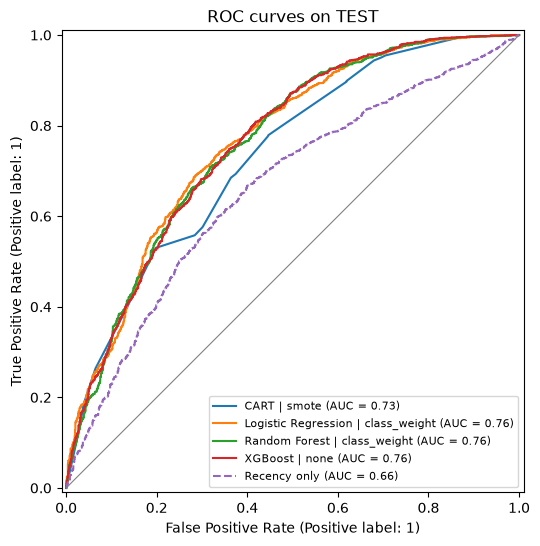

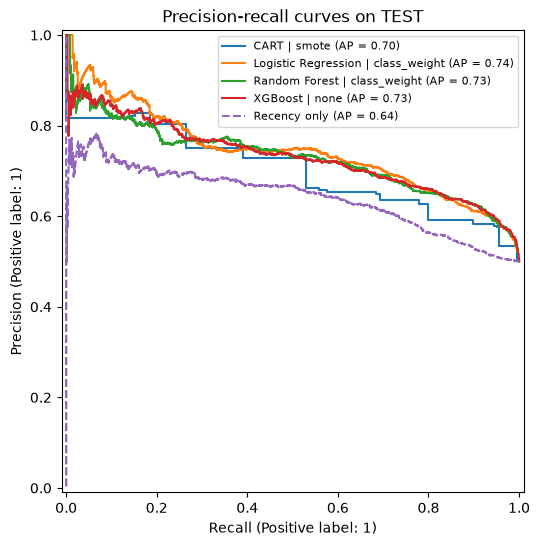

In [7]:
cm.plot_curves(y_test, probabilities, best_keys, test['recency']);

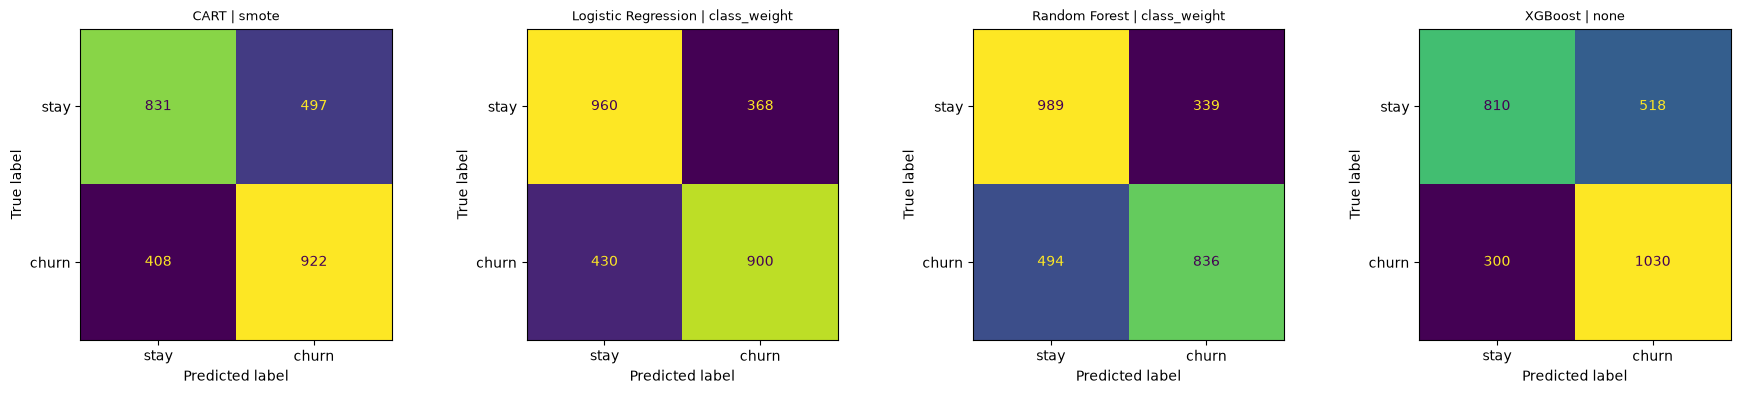

In [8]:
cm.plot_confusion_matrices(y_test, probabilities, best_keys);

**What the curves show:** The ROC and precision-recall curves of Logistic Regression, Random Forest and XGBoost lie almost on top of each other; CART is a little lower and the recency-only dashed line is clearly the lowest. The confusion matrices show the threshold effect: with the 0.5 threshold the models without imbalance handling catch more churners (higher TP, fewer FN) but raise more false alarms (FP).

## 4. Final churn model
Chosen by the highest CV ROC-AUC on TRAIN.

In [9]:
models_only = table.dropna(subset=['cv_roc_auc_train'])
final_row = models_only.loc[models_only['cv_roc_auc_train'].idxmax()]
final_key = f"{final_row['model'].replace(' (Phase 4 reference)', '')} | {final_row['imbalance']}"
print('Final model:', final_key)
final_row

Final model: XGBoost | none


model                                                                     XGBoost
imbalance                                                                    none
cv_roc_auc_train                                                         0.772725
best_params          {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}
precision                                                                0.665375
recall                                                                   0.774436
f1                                                                       0.715775
roc_auc                                                                  0.761896
pr_auc                                                                     0.7309
mean_pred_prob                                                            0.54998
actual_churn_rate                                                        0.500376
TN                                                                            810
FP              

### Lift and gain for the final model

,top_share,customers,churn_rate_in_top,share_of_all_churners_captured,lift
0,top 10%,266,0.831,0.166,1.662
1,top 20%,532,0.767,0.307,1.534


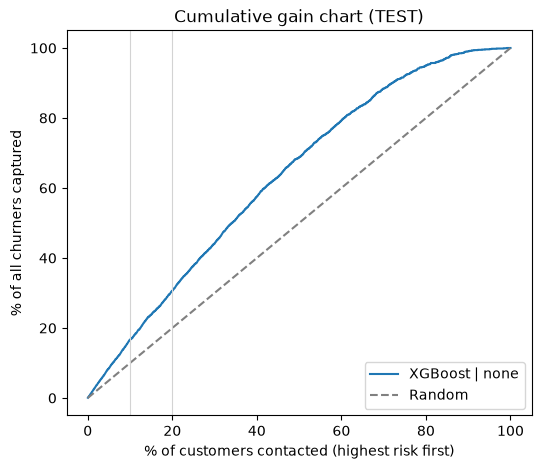

In [10]:
lift = cm.lift_table(y_test, probabilities[final_key])
lift.to_csv(config.TABLES_DIR / 'churn_lift_final_model.csv', index=False)
cm.plot_gain_curve(y_test, probabilities[final_key], final_key)
lift.round(3)

**Lift and gain:** Contacting the 10% highest-risk customers finds 16.6% of all churners (83% of those contacted really churn, lift 1.66 vs random). The top 20% finds 30.7% of churners (lift 1.53). Because half of the test customers churn, the maximum possible lift is only 2.0, so these numbers are moderate, not dramatic.

In [11]:
cm.save_churn_model(fitted[final_key], final_key, list(X_train.columns))
print('Saved', config.CHURN_MODEL)

Saved D:\SEM-7\churn-clv-predictor\models\churn_model.pkl


**Final churn model: XGBoost, no imbalance handling** (learning_rate 0.03, max_depth 3, 200 trees). It has the highest CV ROC-AUC on TRAIN (0.773), and on TEST it scores ROC-AUC 0.762, PR-AUC 0.731, F1 0.716. Honest note: this is a choice among equals: Logistic Regression scores the same (test ROC-AUC 0.764-0.767). We keep XGBoost because it was best in CV (chosen without looking at TEST), it does not need scaling, and it works directly with SHAP's tree explainer in the next phase. Its mean predicted churn probability on test is 0.550 vs the actual 0.50, so its probabilities are about 5 points too high (see Known issues).

*Update (Phase 9b):* this unconstrained model was later replaced by the same XGBoost with monotonic constraints (section 5), because its risk sometimes went down as recency went up.

## 5. Phase 9b: recency sanity check and monotonic constraint
Does churn risk always go UP when a customer has been away longer? We test 4 typical customers (1, 3, 8 and 20 orders) at different recency values, using the saved model through the same `predict_customer` function the app uses. Tenure (first order date) stays fixed while recency changes.

D:\SEM-7\churn-clv-predictor\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,1 order,3 orders,8 orders,20 orders
recency_days,,,,
5,0.772,0.707,0.223,0.094
30,0.830,0.738,0.308,0.130
60,0.858,0.756,0.401,0.229
90,0.892,0.793,0.465,0.295
120,0.922,0.805,0.561,0.611
180,0.927,0.841,0.674,0.704


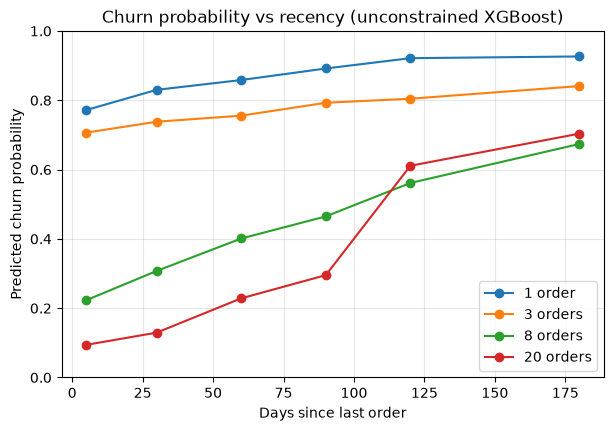

In [12]:
import predict
import model_checks as mc

predict.load_artifacts.cache_clear()          # make sure the model saved above is used
before = mc.recency_table()
before.round(4).to_csv(config.TABLES_DIR / 'recency_sanity_before.csv')
mc.plot_recency(before, 'recency_sanity_before', 'Churn probability vs recency (unconstrained XGBoost)')
before.round(3)

In [13]:
fine_values = list(range(0, 181, 5))
before_drops = mc.decreasing_steps(mc.recency_table(fine_values))
print(f'Places where risk goes DOWN as recency goes UP (every 5 days, 0-180): {len(before_drops)}')
before_drops.sort_values('change').head(8)

Places where risk goes DOWN as recency goes UP (every 5 days, 0-180): 34


,profile,from_recency,to_recency,change
20,8 orders,0,5,-0.1845
10,3 orders,0,5,-0.1053
28,20 orders,0,5,-0.0655
12,3 orders,20,25,-0.0273
1,1 order,20,25,-0.0242
21,8 orders,20,25,-0.0238
27,8 orders,165,170,-0.0148
33,20 orders,165,170,-0.0142


**Before (unconstrained XGBoost):** at the six checked recency values (5, 30, 60, 90, 120, 180 days) risk always rises with recency for all 4 profiles. But on a finer grid (every 5 days from 0 to 180) it goes **down** in 34 places. Most dips are small (under 0.03), but some are large: from 0 to 5 days the 8-order profile drops by 0.18 and the 3-order profile by 0.11. A customer who ordered today being riskier than one who ordered 5 days ago makes no business sense; it is the tree model following noise in the training data.

### Retrain with monotonic constraints
Risk may only **rise** with recency and only **fall** with number of orders, total spent and days since first order. Rule agreed beforehand: keep it only if TRAIN CV ROC-AUC stays within 0.005 of the current model.

In [14]:
mono_model, mono_cv, mono_params = cm.fit_with_cv('XGBoost', 'none', X_train, y_train,
                                                  monotone=config.CHURN_MONOTONE_CONSTRAINTS)
mono_prob = mono_model.predict_proba(X_test)[:, 1]
comparison = pd.DataFrame([
    {'model': 'XGBoost (unconstrained)', 'cv_roc_auc_train': final_row['cv_roc_auc_train'],
     'params': final_row['best_params'], **cm.test_metrics(y_test, probabilities[final_key])},
    {'model': 'XGBoost (monotonic)', 'cv_roc_auc_train': mono_cv, 'params': str(mono_params),
     **cm.test_metrics(y_test, mono_prob)},
])
comparison.to_csv(config.TABLES_DIR / 'churn_monotonic_check.csv', index=False)
cv_drop = final_row['cv_roc_auc_train'] - mono_cv
keep_monotonic = cv_drop <= config.MONOTONE_MAX_CV_DROP
print(f'CV drop: {cv_drop:.4f}  ->  keep monotonic model: {keep_monotonic}')
comparison.drop(columns=['params']).round(4)

CV drop: 0.0023  ->  keep monotonic model: True


,model,cv_roc_auc_train,precision,recall,f1,roc_auc,pr_auc,mean_pred_prob,actual_churn_rate,TN,FP,FN,TP
0,XGBoost (unconstrained),0.7727,0.6654,0.7744,0.7158,0.7619,0.7309,0.5500,0.5004,810,518,300,1030
1,XGBoost (monotonic),0.7704,0.6701,0.7391,0.7029,0.7567,0.7303,0.5411,0.5004,844,484,347,983


Saved the monotonic model as the final churn model


Places where risk goes DOWN as recency goes UP (every 5 days, 0-180): 7


,1 order,3 orders,8 orders,20 orders
recency_days,,,,
5,0.768,0.689,0.215,0.078
30,0.830,0.722,0.282,0.111
60,0.861,0.746,0.370,0.143
90,0.899,0.786,0.409,0.167
120,0.928,0.802,0.478,0.315
180,0.937,0.871,0.608,0.432


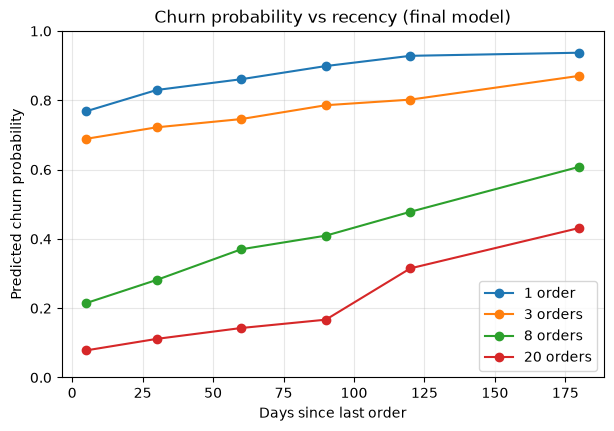

In [15]:
if keep_monotonic:
    cm.save_churn_model(mono_model, 'XGBoost | none | monotonic', list(X_train.columns))
    predict.load_artifacts.cache_clear()
    print('Saved the monotonic model as the final churn model')
after = mc.recency_table()
after.round(4).to_csv(config.TABLES_DIR / 'recency_sanity_after.csv')
mc.plot_recency(after, 'recency_sanity_after', 'Churn probability vs recency (final model)')
after_drops = mc.decreasing_steps(mc.recency_table(fine_values))
print(f'Places where risk goes DOWN as recency goes UP (every 5 days, 0-180): {len(after_drops)}')
after.round(3)

,top_share,customers,churn_rate_in_top,share_of_all_churners_captured,lift
0,top 10%,266,0.823,0.165,1.647
1,top 20%,532,0.767,0.307,1.534


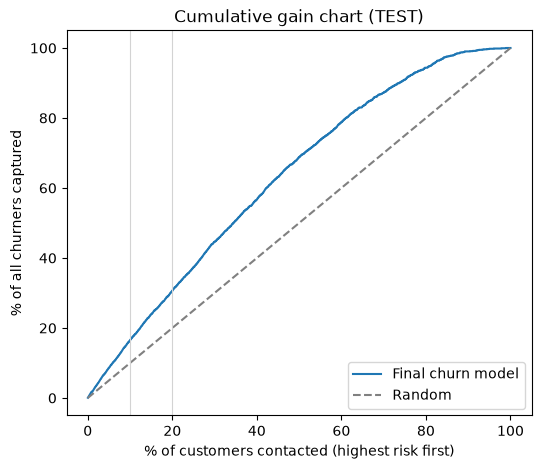

In [16]:
final_prob = mono_prob if keep_monotonic else probabilities[final_key]
lift_final = cm.lift_table(y_test, final_prob)
lift_final.to_csv(config.TABLES_DIR / 'churn_lift_final_model.csv', index=False)
cm.plot_gain_curve(y_test, final_prob, 'Final churn model')
lift_final.round(3)

**Result:** the monotonic model (risk can only rise with recency and only fall with orders, total spent and days since first order) has TRAIN CV ROC-AUC 0.7704 vs 0.7727, a drop of 0.0023, inside the agreed 0.005 limit, so **it is kept as the final churn model**. On TEST it is slightly lower: ROC-AUC 0.757 vs 0.762, PR-AUC 0.730 vs 0.731, F1 0.703 vs 0.716; its mean predicted probability (0.541) is a bit closer to the real churn rate (0.50) than before (0.550). Lift is almost unchanged: the top 10% contains 16.5% of all churners (lift 1.65), the top 20% contains 30.7% (lift 1.53).

On the fine grid the number of downward steps falls from 34 to 7. All 7 remaining dips are in the 1-order profile and are tiny (at most 0.0095). They are expected: for a one-order customer, days since first order equals days since last order, so both move together, and the constraints push them in opposite directions (recency raises risk, tenure lowers it). The constraint guarantees the direction only when the other features stay the same.